# Solutions

## Probability distributions Exercise 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

seed = 512
rng = np.random.default_rng(seed)

In [2]:
# We'll need this a few times, so write a function to take the x values and 
# plot a histogram comparing to the analytic function func
def plot_distribution(x, func, y_log=True):
    plt.clf()
    plt.hist(x, density=True, bins=100, histtype = 'step')
    xx = np.linspace(min(x),max(x),100)
    plt.plot(xx, func(xx),':')
    if y_log:
        plt.yscale('log')
    plt.xlabel('x')
    plt.show()

### Rejection method

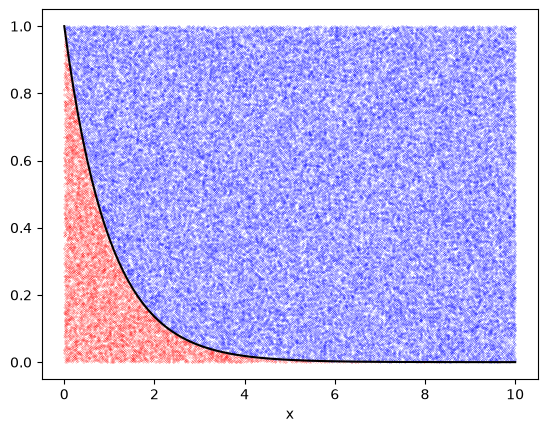

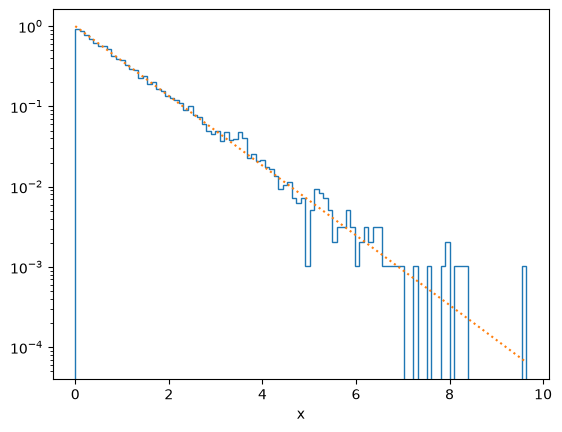

In [3]:
def f(x):
    return np.exp(-x)

xmax = 10
x = xmax * rng.uniform(size = 10**5)    # Generate x values up to xmax
y = rng.uniform(size = 10**5)

# Reject
ind = np.where(y <= f(x))
ind2 = np.where(y > f(x))

# Plot the points to show which ones are accepted and which rejected
plt.plot(x[ind2],y[ind2], 'bo', ms=0.1)
plt.plot(x[ind],y[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary (see below)
xx = np.linspace(0.0,xmax,100)
plt.plot(xx, f(xx), 'k')
plt.xlabel('x')
plt.show()

plot_distribution(x[ind], f)

### Transformation method

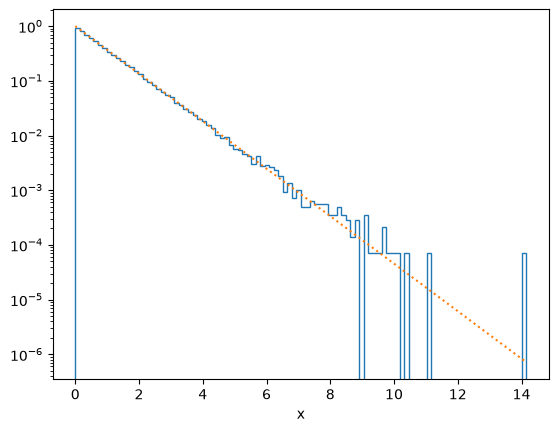

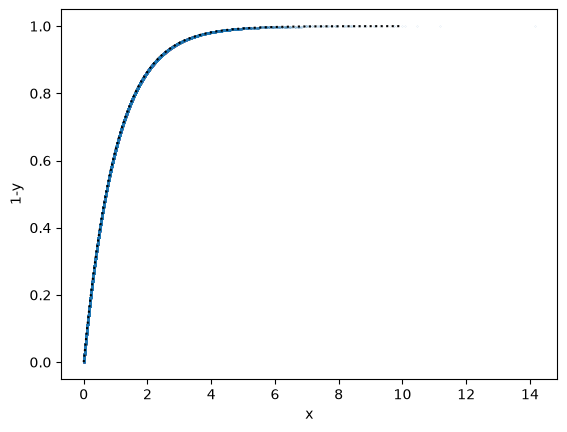

In [4]:
y = rng.uniform(size = 10**5)

x = - np.log(y)

# Plot the distribution of x and compare with the exponential distribution
plot_distribution(x, f)

# Plot 1-y(x) to illustrate that y is related to the cumulative distribution function
plt.clf()
plt.plot(x, 1-y, '.', ms=0.1)
xx = np.linspace(0.0,xmax,100)
plt.plot(xx, 1-f(xx), 'k:')
plt.xlabel('x')
plt.ylabel('1-y')
plt.show()

### Ratio of uniforms

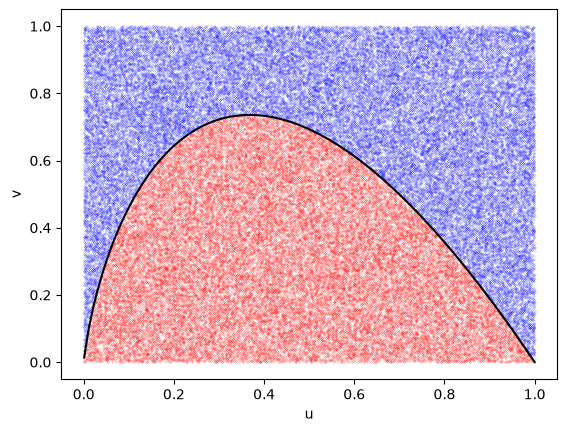

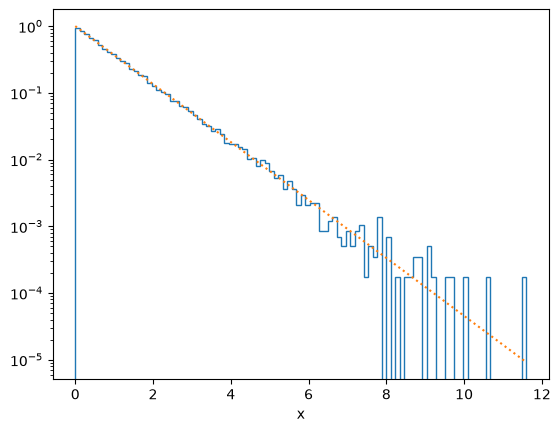

In [5]:
def f(x):
    return np.exp(-x)

u = rng.uniform(size = 10**5)
v = rng.uniform(size = 10**5)
# choose which points to keep -- we renormalize f here to drop the factor of 2
ind = np.where(u <= np.sqrt(f(v/u)))
ind2 = np.where(u > np.sqrt(f(v/u)))
x = v[ind]/u[ind]

# Plot the points to show which ones are accepted and which rejected
plt.plot(u[ind2],v[ind2], 'bo', ms=0.1)
plt.plot(u[ind],v[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary (see below)
uu = np.linspace(0.001,1.0,100)
plt.plot(uu, -2*uu*np.log(uu), 'k')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

# Plot the distribution f(x)
plot_distribution(x, f)

The black curve above separates the accepted and rejected points. To derive this, start with

$$u \leq \sqrt{\exp\left(-{v\over u}\right)}$$

and invert this to get $v$:

$$u^2 \leq \exp\left(-{v\over u}\right)$$

$$2\ln u \leq -{v\over u}$$

$$2 u \ln u \leq -v$$

$$v \leq -2 u \ln u$$

which is plotted as the black curve in the figure.

## Probability distributions Exercise 2

### Power law 

$f(x) = C x^{-\alpha}$ for $a<x<b$, where $C$ is the normalization factor,

$$\int_a^b C x^{-\alpha} dx = 1\Rightarrow C = (1-\alpha)\left[b^{1-\alpha}-a^{1-\alpha}\right]^{-1}$$

$${dy\over dx} = C x^{-\alpha} \Rightarrow y = {C\over 1-\alpha} \left[x^{1-\alpha}\right]^x_a  = {x^{1-\alpha} - a^{1-\alpha}\over b^{1-\alpha} - a^{1-\alpha}}$$

$$\Rightarrow x =  \left[b^{1-\alpha}y + a^{1-\alpha} (1-y)\right]     ^{1/(1-\alpha)}$$

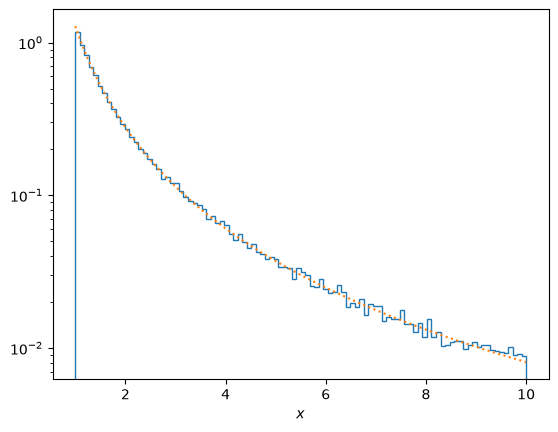

In [6]:
# Power law by transformation
def f(x, a, C):
    return C * x**(-a)

alpha = 2.2
a = 1
b = 10
n = 1-alpha
C = n/(b**n - a**n)

y = rng.uniform(size = 10**5)
x = (b**n*y + a**n*(1-y))**(1/n)

plt.hist(x, density=True, bins=100, histtype = 'step')

# plot the analytic solution, the multiplicative factors account
# for our x-axis being in log_10(x)
xx = np.linspace(a,b,100)
plt.plot(xx, f(xx,alpha,C),':')
plt.yscale('log')
plt.xlabel(r'$x$')
plt.show()

### Lorentzian (Cauchy distribution) by transformation method and ratio of uniforms

$$f(x) = {1\over \pi}{1\over 1+x^2}$$

for $-\infty<x<\infty$

$${dy\over dx} = {1\over \pi}{1\over 1+x^2}\Rightarrow y = {1\over \pi}\left[\arctan(x)\right]^x_{-\infty} = {1\over \pi}\arctan(x) + {1\over 2}$$

$$\Rightarrow x = \tan\left(\pi\left(y-{1\over 2}\right)\right)$$

Number of samples between +-100 = 99341


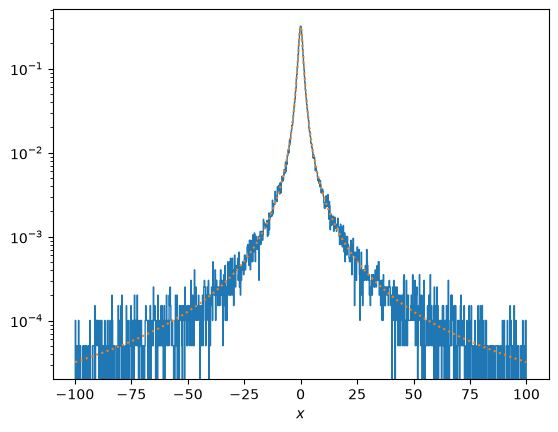

In [7]:
# Lorentzian by transformation method

import scipy.integrate

def f(x):
    return 1 / (np.pi * (1+x**2))

y = rng.uniform(size = 10**5)
x = np.tan(np.pi*(y-0.5))

# trim the x values to focus on the center of the distribution
xtrim = 100.0
x = x[np.where(np.logical_and(x<xtrim, x>-xtrim))]
# and also calculate the new normalization between these limits
norm, err = scipy.integrate.quad(f, -xtrim, xtrim)
print('Number of samples between +-%g = %d' % (xtrim, len(x)))

plt.hist(x, density=True, bins=1000, histtype = 'step')
xx = np.linspace(min(x),max(x),1000)
plt.plot(xx, f(xx)/norm,':')
plt.yscale('log')
plt.xlabel(r'$x$')
plt.show()

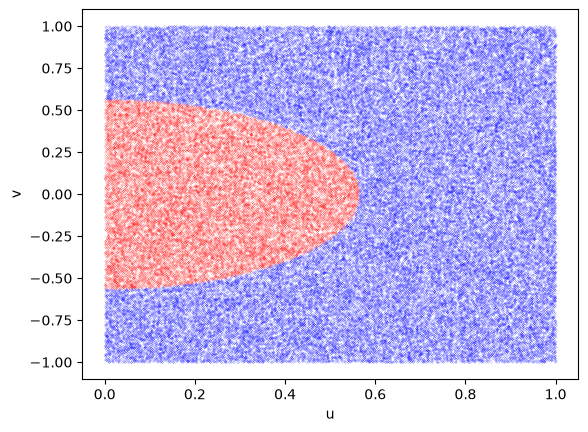

Number of samples between +-100 = 24557


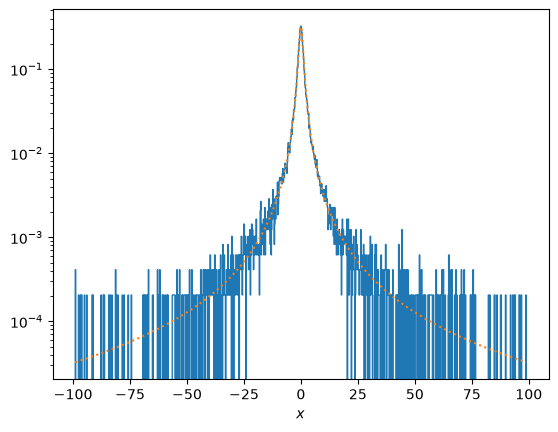

In [8]:
# Lorentzian by ratio of uniforms
def f(x):
    return 1 / (np.pi * (1+x**2))

u = rng.uniform(size = 10**5)
v = -1.0 + 2.0*rng.uniform(size = 10**5)
# choose which points to keep
ind = np.where(u <= np.sqrt(f(v/u)))
ind2 = np.where(u > np.sqrt(f(v/u)))
x = v[ind]/u[ind]

# Plot the points to show which ones are accepted and which rejected
plt.plot(u[ind2],v[ind2], 'bo', ms=0.1)
plt.plot(u[ind],v[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary (see below)
#uu = np.linspace(0.001,1.0,100)
#plt.plot(uu, -2*uu*np.log(uu), 'k')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

# trim the x values to focus on the center of the distribution
xtrim = 100.0
x = x[np.where(np.logical_and(x<xtrim, x>-xtrim))]
# and also calculate the new normalization between these limits
norm, err = scipy.integrate.quad(f, -xtrim, xtrim)
print('Number of samples between +-%g = %d' % (xtrim, len(x)))

# Plot the distribution f(x)
plt.hist(x, density=True, bins=1000, histtype = 'step')
xx = np.linspace(min(x),max(x),1000)
plt.plot(xx, f(xx)/norm,':')
plt.yscale('log')
plt.xlabel(r'$x$')
plt.show()

### Gaussian by ratio of uniforms

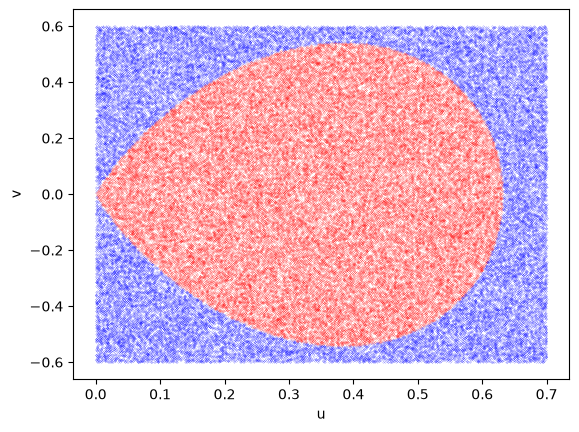

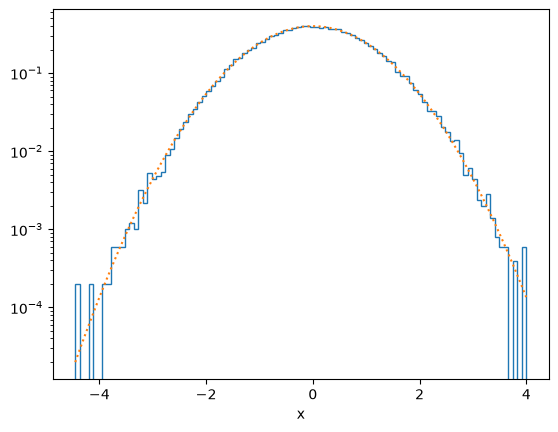

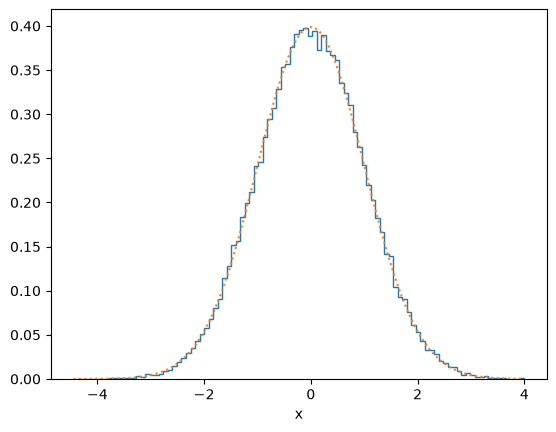

In [9]:
# Gaussian by ratio of uniforms
def f(x):
    return np.exp(-x**2/2)/ np.sqrt(2*np.pi)

u = 0.7*rng.uniform(size = 10**5)
v = -0.6 + 1.2*rng.uniform(size = 10**5)
# choose which points to keep
ind = np.where(u <= np.sqrt(f(v/u)))
ind2 = np.where(u > np.sqrt(f(v/u)))
x = v[ind]/u[ind]

# Plot the points to show which ones are accepted and which rejected
plt.plot(u[ind2],v[ind2], 'bo', ms=0.1)
plt.plot(u[ind],v[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary (see below)
#uu = np.linspace(0.001,1.0,100)
#plt.plot(uu, -2*uu*np.log(uu), 'k')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

plot_distribution(x, f)
plot_distribution(x, f, y_log=False)

### Rejection method with and without importance sampling

Acceptance fraction = 0.2789


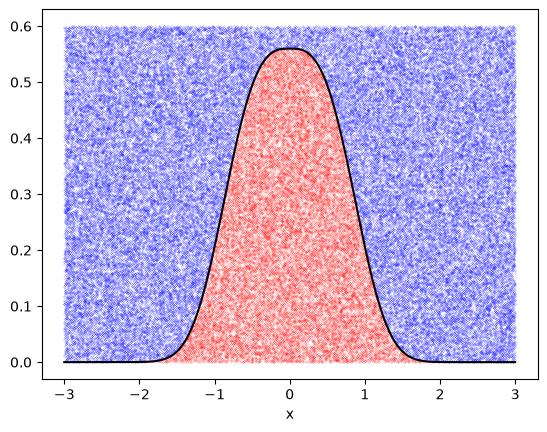

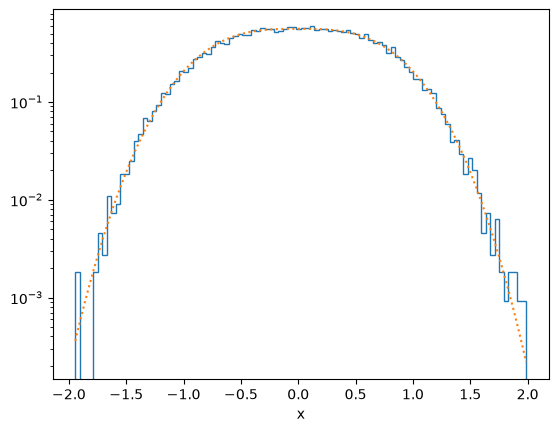

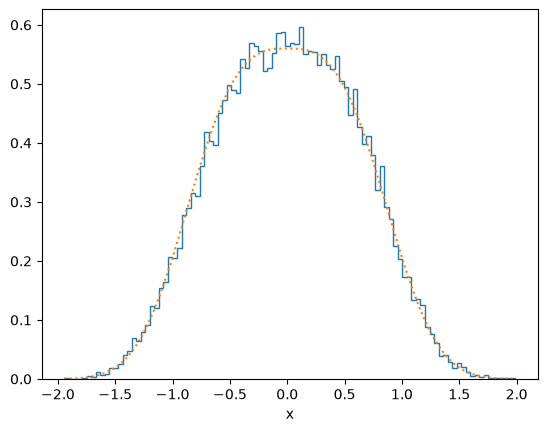

In [10]:
# Rejection method for exp(-|x^3|)

def f(x):
    return np.exp(-np.abs(x**3))/(2*0.89298)

xmax = 3
x = -xmax + 2*xmax*rng.uniform(size = 10**5)    # Generate x values between +-xmax
y = 0.6*rng.uniform(size = 10**5)

# Reject
ind = np.where(y <= f(x))
ind2 = np.where(y > f(x))

print("Acceptance fraction = %g" % (len(x[ind])/len(x)))

# Plot the points to show which ones are accepted and which rejected
plt.plot(x[ind2],y[ind2], 'bo', ms=0.1)
plt.plot(x[ind],y[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary
xx = np.linspace(-xmax,xmax,1000)
plt.plot(xx, f(xx), 'k')
plt.xlabel('x')
plt.show()

plot_distribution(x[ind], f)
plot_distribution(x[ind], f, y_log = False)


Acceptance fraction = 0.66969


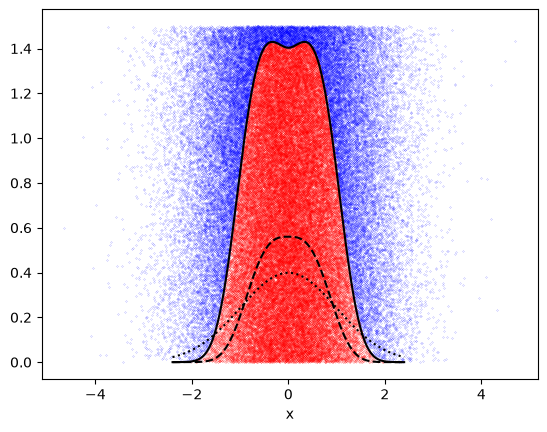

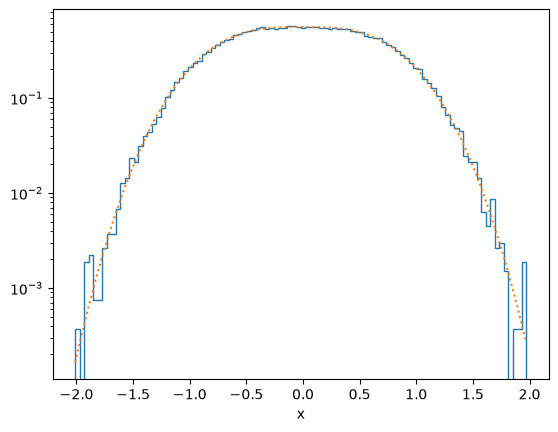

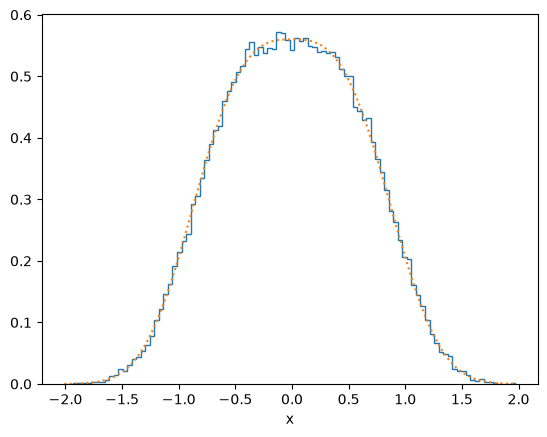

In [11]:
# Rejection method for exp(-|x^3|) but now use importance sampling

def f(x):
    return np.exp(-np.abs(x**3))/(2*0.89298)

def p(x):
    return np.exp(-x**2/2)/(np.sqrt(2*np.pi))

xmax = 2.4
x = rng.normal(size = 10**5)    # Generate x values between +-xmax
y = 1.5*rng.uniform(size = 10**5)

# Reject
ind = np.where(y <= f(x)/p(x))
ind2 = np.where(y > f(x)/p(x))

print("Acceptance fraction = %g" % (len(x[ind])/len(x)))

# Plot the points to show which ones are accepted and which rejected
plt.plot(x[ind2],y[ind2], 'bo', ms=0.1)
plt.plot(x[ind],y[ind], 'ro', ms=0.1)
# Plot the analytic solution for the boundary
xx = np.linspace(-xmax,xmax,1000)
plt.plot(xx, f(xx), 'k--')
plt.plot(xx, p(xx), 'k:')
plt.plot(xx, f(xx)/p(xx), 'k')
plt.xlabel('x')
plt.show()

plot_distribution(x[ind], f)
plot_distribution(x[ind], f, y_log=False)

## Sampling $\exp(-|x^3|)$ with Metropolis-Hastings

Acceptance fraction = 0.2599
normalization =  0.8929795115692494


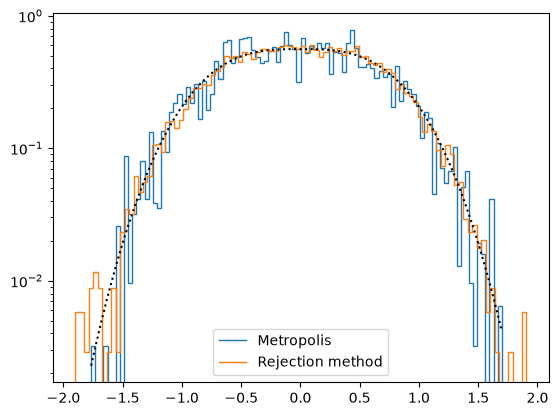

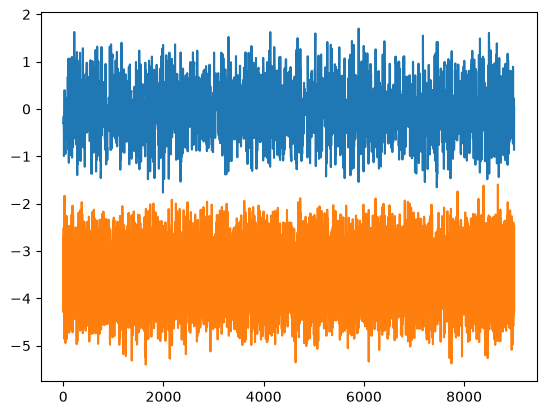

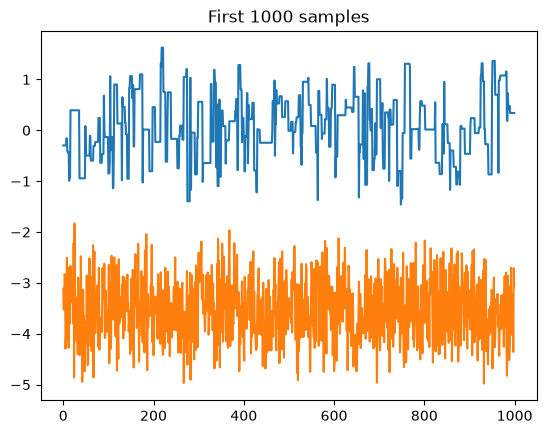

<Figure size 640x480 with 0 Axes>

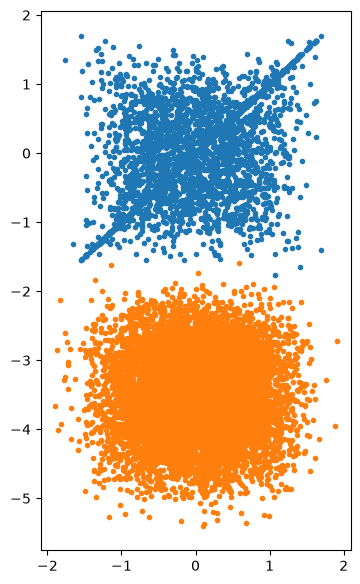

In [12]:
import scipy.integrate

def f(x):
    return np.exp(-np.abs(x**3))

N = 10**4 # generate N samples

x = np.zeros(N)
x[0] = -3  # starting point

count = 0

for i in range(N-1):
    
    # Proposal
    x_try = x[i] + rng.normal(scale = 3)
    # Accept the move or stay where we are
    u = rng.uniform()
    if u <= f(x_try) / f(x[i]):
        x[i+1] = x_try
        count = count + 1
    else:
        x[i+1] = x[i]

print("Acceptance fraction = %g" % (count/N,))

# Remove the first part of the chain (burn-in)
x = x[N//10:]

# Generate the same number of samples using the rejection method with uniform sampling
xmax = 4
xu = -xmax + 2*xmax*rng.uniform(size = 10*N)    # Generate x values between +-xmax
y = rng.uniform(size = 10*N)
xu = xu[np.where(y <= f(xu))]  
xu = xu[:9*N//10]
        
# Plot the distribution        
counts, bins = np.histogram(x, bins=100, density = True)
plt.stairs(counts, bins, label = 'Metropolis')    

counts, bins = np.histogram(xu, bins=100, density = True)
plt.stairs(counts, bins, label = 'Rejection method')  
norm,_ = scipy.integrate.quad(f,-np.inf,np.inf)
print("normalization = ", norm/2)
xx = np.linspace(min(x),max(x),1000)
plt.plot(xx, f(xx)/norm, 'k:')

plt.yscale('log')

plt.legend()
plt.show()

# Plot the entire chain
plt.clf()
plt.plot(x)
plt.plot(xu - 3.5)
plt.show()

# Plot the first 1000 samples to see the time series
plt.clf()
plt.plot(x[:1000])
plt.plot(xu[:1000] - 3.5)
plt.title('First 1000 samples')
plt.show()

# Plot the point-to-point correlation
plt.clf()
plt.figure(figsize=(4,7))
plt.plot(x[:-1], x[1:], '.')
plt.plot(xu[:-1], xu[1:] - 3.5, '.')
plt.show()

Notes:
- We've taken an initial value of $x=0$, so right in the middle of the distribution. If you change this to something more outside the peak, e.g. $x=5$, you'll see the burn in phase where the chain walks from $x=5$ towards the main distribution. In the example above, I've thrown away the first 10% of the samples to try to remove this phase. You should find that you still get a good distribution once the burn-in phase is removed.
- The histogram compares the distribution of the MCMC samples with the same number of samples from a rejection method. One thing to notice is that the variance of the MCMC sample is larger than the rejection method. If you change the number of rejection method samples to match the number of *accepted* points in the MCMC then you should find the agreement is much better. What's happening is that successive points in the MCMC chain are correlated, reducing the effective number of independent samples from the distribution. You can see this comparing the MCMC and rejection method results in the "first 1000 samples" plot or in the $x_{n+1}$ vs $x_n$ plot. The chain looks much more correlated.
- Try changing the proposal distribution width and see what happens. For large values, the jumps are rejected much more often and the diagonal line in the $x_{n+1}$-$x_n$ plot becomes more prominent. For small values, the correlations between successive points increase, so you should see the cloud of points becoming more diagonal in shape. The optimal jump size should allow the points to explore the full probability distribution but still get a reasonable acceptance fraction.
- The way the MCMC chain is constructed means that the points themselves are not independent random draws from the distribution, so don't for example use this as a random sequence. But the values in the chain do appear in the correct frequencies to represent the distribution $f(x)$, so they can be used for example to plot the distribution or calculate averages of quantities, e.g. $$<A> = \int dx f(x) A(x) = {1\over N}\sum_i A(x_i),$$ where the sum is over the samples.

## MCMC exoplanet fit

In [13]:
def rv(t, P, x):
    # Calculates the radial velocity of a star orbited by a planet
    # at the times in the vector t
    
    # extract the orbit parameters
    # P, t and tp in days, mp in Jupiter masses, v0 in m/s  
    mp, e, omega, tp, v0 = x
        
    # mean anomaly
    M = 2*np.pi * (t-tp) / P
    
    # velocity amplitude
    K = 204 * P**(-1/3) * mp  / np.sqrt(1.0-e*e) # m/s
    
    # solve Kepler's equation for the eccentric anomaly E - e * np.sin(E) = M
    # Iterative method from Heintz DW, "Double stars", Reidel, 1978
    # first guess
    E = M + e*np.sin(M)  + ((e**2)*np.sin(2*M)/2)
    while True:
        E0 = E 
        M0 = E0 - e*np.sin(E0)
        E = E0 + (M-M0)/(1.0 - e*np.cos(E0))
        if np.max(np.abs((E-E0))) < 1e-6:
            break
        
    # evaluate the velocities
    theta = 2.0 * np.arctan( np.sqrt((1+e)/(1-e)) * np.tan(E/2))
    vel = v0 + K * ( np.cos(theta + omega) + e * np.cos(omega))
    
    return vel

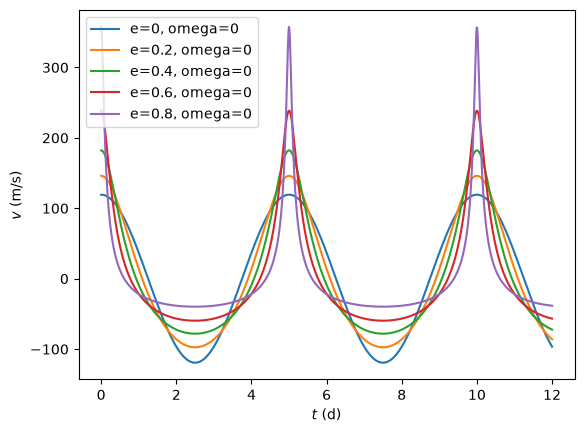

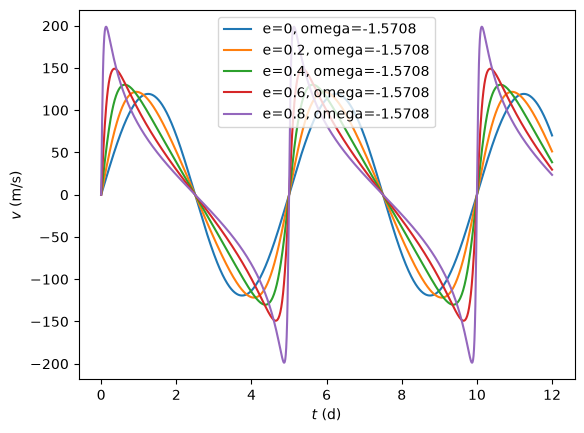

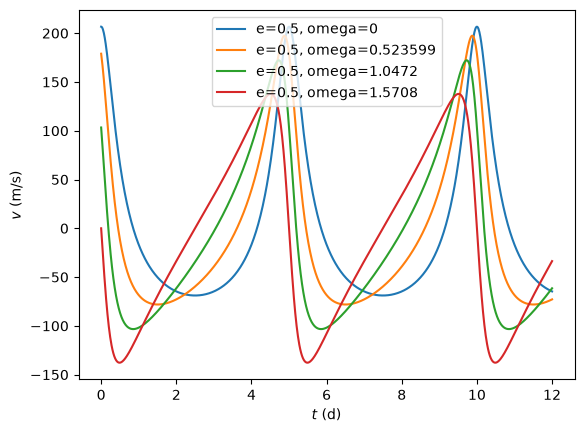

In [14]:
# Make some plots to show what the velocity curves look like
t = np.linspace(0,12,num=1000)

for e in np.arange(0.0,1.0,0.2):
    v = rv(t, 5.0, [1.0, e, 0.0, 0.0, 0.0])
    plt.plot(t,v, label='e=%g, omega=%g' % (e,0.0))

plt.ylabel(r'$v\ (\mathrm{m/s})$')
plt.xlabel(r'$t\ (\mathrm{d})$')
plt.legend()
plt.show()

plt.clf()
for e in np.arange(0.0,1.0,0.2):
    v = rv(t, 5.0, [1.0, e, -np.pi/2, 0.0, 0.0])
    plt.plot(t,v, label='e=%g, omega=%g' % (e,-np.pi/2))

plt.ylabel(r'$v\ (\mathrm{m/s})$')
plt.xlabel(r'$t\ (\mathrm{d})$')
plt.legend()
plt.show()

plt.clf
for omega in np.linspace(0.0,np.pi/2,4):
    v = rv(t, 5.0, [1.0, 0.5, omega, 0.0, 0.0])
    plt.plot(t,v, label='e=%g, omega=%g' % (0.5, omega))

plt.ylabel(r'$v\ (\mathrm{m/s})$')
plt.xlabel(r'$t\ (\mathrm{d})$')
plt.legend()
plt.show()

In [15]:
def f(x, tobs, vobs, eobs):
    # returns -chisq/2 for this set of parameters
    chisq = np.sum(((vobs-rv(tobs, P, x))/eobs)**2)
    return -chisq/2

# Observations
# These are for HD145675 from Butler et al. 2003
tobs, vobs, eobs = np.loadtxt('rvs.txt', unpack=True)

# Number of samples to generate
N = 10**5
x = np.zeros((N, 5))

# initial guess
# P, mp, e, omega, tp, v0 
P = 1724
x[0] = [1.0, 0.0, 0.0, 0.0, 0.0]
# and the widths for the jumps
widths = (0.03, 0.03, 0.03, 3.0, 1.0)

count = 0

for i in range(N-1):
    
    # Proposal: choose a parameter at random to jump in
    ii = np.random.randint(0, 5)
    x_try = np.copy(x[i])
    x_try[ii] += rng.normal(scale = widths[ii])
    
    # Accept the move or stay where we are
    u = rng.uniform()
    if u <= np.exp(f(x_try, tobs,vobs,eobs) - f(x[i], tobs,vobs,eobs)):
        x[i+1] = np.copy(x_try)
        count = count + 1
    else:
        x[i+1] = np.copy(x[i])

print("Acceptance fraction = %g" % (count/N,))
print("Last set of parameters = ", x[-1])

Acceptance fraction = 0.39886
Last set of parameters =  [ 4.84748421e+00  3.68845121e-01  2.48543694e-01 -3.72531163e+02
 -2.80609426e+01]


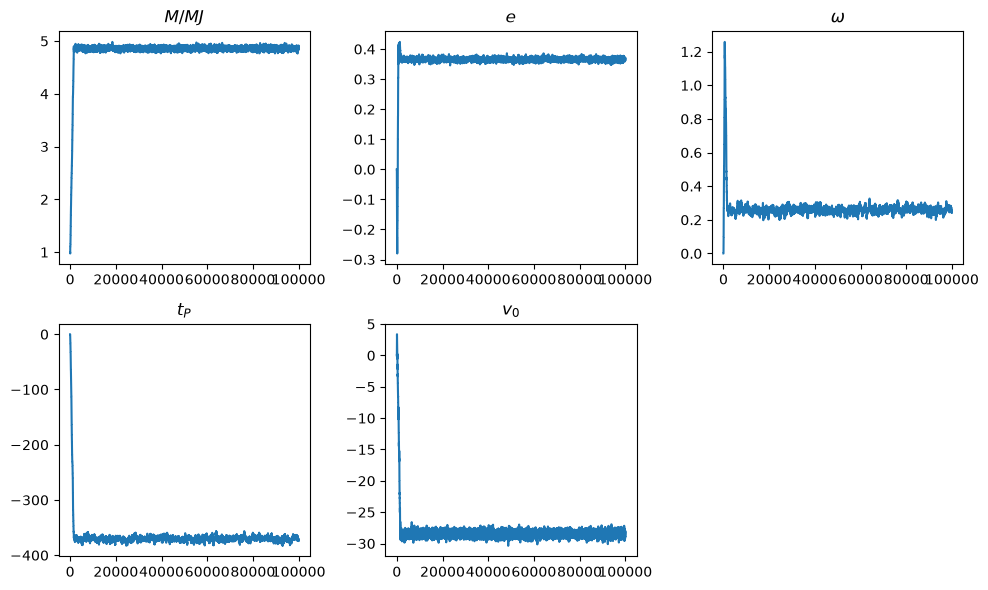

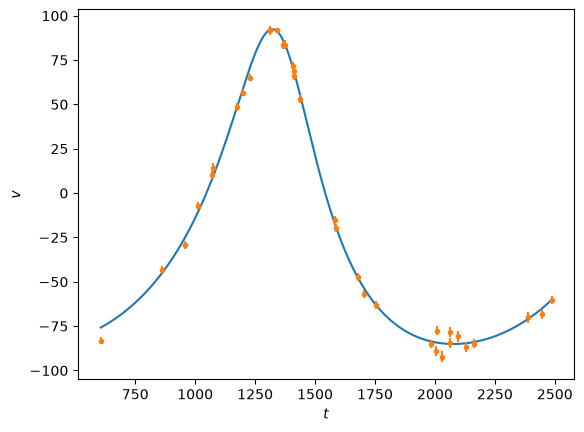

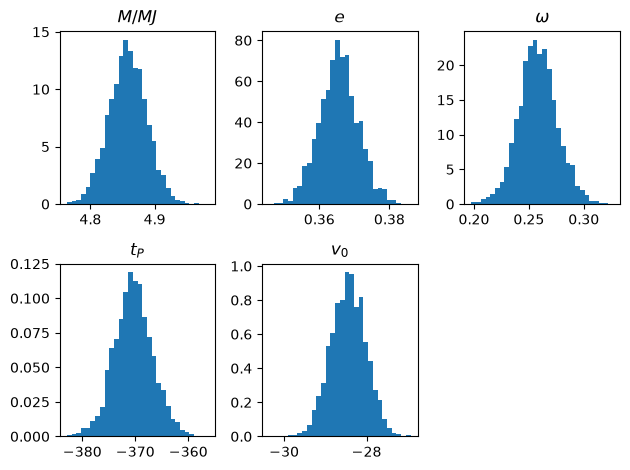

In [16]:
plt.figure(figsize=(10,6))

titles = (r'$M/MJ$', r'$e$', r'$\omega$', r'$t_P$', r'$v_0$')
for i, title in enumerate(titles):
    plt.subplot(2,3,i+1)
    plt.title(title)
    plt.plot(list(range(N)), x[:, i])
plt.tight_layout()
plt.show()

# Reject the burn in phase
x1 = x[int(N//10):]

plt.clf()
t = np.linspace(tobs[0], tobs[-1], 1000)
#for params in x1[::100]:
#    plt.plot(t, rv(t,P, params), 'k', alpha=0.05)    
plt.plot(t, rv(t,P, x[-1]), 'C0')
plt.plot(tobs, vobs, 'C1.')
plt.errorbar(tobs, vobs, eobs, fmt='none', ecolor='C1')
plt.ylabel(r'$v$')
plt.xlabel(r'$t$')
plt.show()

plt.clf()
for i, title in enumerate(titles):
    plt.subplot(2,3,i+1)
    plt.title(title)
    plt.hist(x1[:, i], density=True, bins=30)
plt.tight_layout()
plt.show()

The nice thing about MCMC is that it is very easy to marginalize over one or more of the parameters in a distribution. For example, if you have samples from a two-dimensional probability distribution $f(x,y)$, then you might want to find
$$g(x) = \int dy\, f(x,y)$$
which is the probability density of $x$. We say that we **marginalize** over the unwanted parameters. Note that if $f(x,y)$ is normalized, then so is $g(x)$
$$\int dx\, g(x) = \int dx\, dy\, f(x,y) = 1.$$

If we have an MCMC chain that samples $f(x,y)$, to obtain $g(x)$, you just have to bin the samples in $x$. A way to think about this is that you collapse the 2D space of samples onto the $x$-axis. This is equivalent to doing the $y$-integration but without integrating!

The histograms above show the distribution for each of the 5 parameters $M,e,\omega,t_P,v_0$, in each case marginalized over the other 4 parameters.

A corner plot is a nice way to show not only the 1D histograms but also the 2D marginalized distributions of each possible pair of parameters (in each case marginalized over the other three). This allows us to see correlations: for example, we can see below that the fitted values of $t_P$ and $\omega$ are correlated.

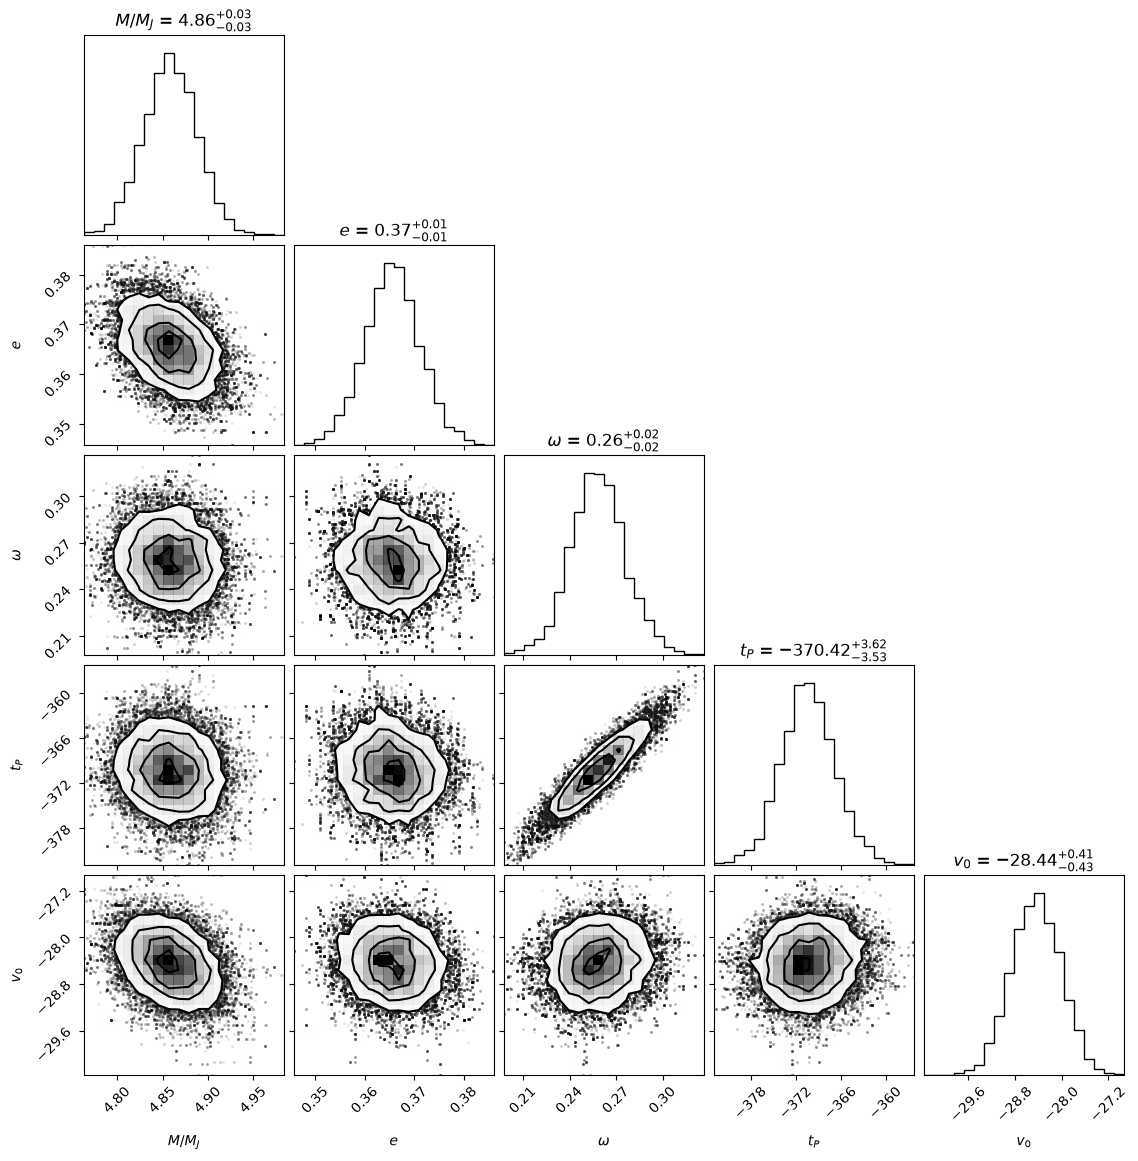

In [17]:
# https://corner.readthedocs.io/en/latest/
import corner

figure = corner.corner(x1, 
        labels = [r'$M/M_J$', r'$e$', r'$\omega$', r'$t_P$', r'$v_0$'], 
        bins = 20, show_titles=True)